In [ ]:
import os
import glob
import shutil
from ultralytics import YOLO
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

best_weights = '/content/drive/MyDrive/ADAS_YOLOv26_Model/vision_yolo26_scratch_100epochs/weights/best.pt'
if not os.path.exists(best_weights):
    raise FileNotFoundError(f"❌ Weights not found at specified path: {best_weights}")
print(f"✅ Weights locked to ADAS 100-epoch model: {best_weights}")

src_dir = "/content/drive/MyDrive/ADAS_17Classes_Dataset"
local_dir = "/content/adas_training_local"

if os.path.exists(local_dir):
    shutil.rmtree(local_dir)
shutil.copytree(src_dir, local_dir)

mapping_full = {15: 13, 16: 12}
MAX_EXTRA_PEDESTRIANS = 500
added_pedestrians_count = 0

for split in ['train', 'valid', 'test']:
    lbl_dir = os.path.join(local_dir, split, 'labels')
    if not os.path.exists(lbl_dir):
        continue
    for lbl_path in glob.glob(os.path.join(lbl_dir, "*.txt")):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue

            cls_id = int(parts[0])
            rest_of_box = parts[1:]

            if cls_id == 14:
                if added_pedestrians_count < MAX_EXTRA_PEDESTRIANS:
                    cls_id = 3
                    added_pedestrians_count += 1
                else:
                    continue
            elif cls_id in mapping_full:
                cls_id = mapping_full[cls_id]

            new_line = f"{cls_id} " + " ".join(rest_of_box) + "\n"
            new_lines.append(new_line)

        with open(lbl_path, 'w') as f:
            f.writelines(new_lines)

yaml_path = os.path.join(local_dir, "data.yaml")
yaml_content = f"""path: {local_dir}
train: train/images
val: valid/images

nc: 14

names:
  0: loose_gravel
  1: no_entry
  2: no_parking_waiting
  3: pedestrian
  4: pedestrian_crossing_sign
  5: speed_100
  6: speed_30
  7: speed_40
  8: speed_50
  9: speed_60
  10: speed_80
  11: speed_bump
  12: stop_sign
  13: traffic_signal
"""

with open(yaml_path, 'w', encoding='utf-8') as f:
    f.write(yaml_content)

print(f"📊 Dataset preprocessing completed. Integrated {added_pedestrians_count} auxiliary pedestrian samples for distribution equilibrium.")

model = YOLO(best_weights)

model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    cls=2.0,
    mosaic=1.0,
    mixup=0.15,
    patience=15,
    save=True,
    project='/content/drive/MyDrive/ADAS_Training_Results',
    name='adas_14cls_balanced_finetune_50ep'
)

Mounted at /content/drive
✅ Weights locked to ADAS 100-epoch model: /content/drive/MyDrive/ADAS_YOLOv26_Model/vision_yolo26_scratch_100epochs/weights/best.pt
📊 Dataset preprocessing completed. Integrated 500 auxiliary pedestrian samples for distribution equilibrium.
Ultralytics 8.4.148 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=2.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/adas_training_local/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7badded784b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.0

In [ ]:
!pip install ultralytics -q

import os
from google.colab import drive
from ultralytics import YOLO

print("Mounting Google Drive...")
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

dataset_yaml = "/content/dataset/data.yaml"

if not os.path.exists(dataset_yaml):
    os.makedirs('/content/dataset', exist_ok=True)
    print("Extracting dataset for proper INT8 calibration...")
    !unzip -q "/content/drive/MyDrive/Offline Arabic ADAS.zip" -d /content/dataset

best_weights_path = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"

if not os.path.exists(best_weights_path):
    raise FileNotFoundError(f"Weights file not found at: {best_weights_path}")

print(f"Loading model weights from: {best_weights_path}")
model = YOLO(best_weights_path)

print("Initiating proper INT8 quantization and export using your ADAS dataset calibration...")
exported_file = model.export(
    format="litert",
    quantize="int8",
    data=dataset_yaml,
    imgsz=640
)

print("\nModel successfully exported and calibrated with your dataset.")
print(f"Final output path: {exported_file}")

Mounting Google Drive...
Extracting dataset for proper INT8 calibration...
replace /content/dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
Loading model weights from: /content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt
Initiating proper INT8 quantization and export using your ADAS dataset calibration...
Ultralytics 8.4.149 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 120 layers, 2,377,566 parameters, 0 gradients, 5.3 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 18, 8400) (5.1 MB)
LiteRT: collecting INT8 calibration images from 'data=/content/dataset/data.yaml'
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 474.1±294.9 MB/s, size: 23.1 KB)
val: Scanning /content/d

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:01) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


(00:03) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

... (21 outputs left out)

(00:00) [ DONE] Write Model to 
/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/usr/local/lib/python3.13/dist-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
Applying Transformations to tensors:: 100%|██████████| 659/659 [00:00<00:00, 17444.50it/s]


Model name: /content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite
Original model size: 9.39 MiB
Quantized model size: 2.76 MiB
Quantization Ratio: 0.29 (3.4x smaller)
Total time: 292.79 ms
LiteRT: export success ✅ 1578.5s, saved as '/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite' (2.8 MB)

Export complete (1579.4s)
Results saved to /content/drive/.shortcut-targets-by-id/1UyDXo8Xj8mzf88MmXJVDDrFxbNcuvWfG/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best_int8.tflite imgsz=640 data=/content/adas_training_local/data.yaml  
Visualize:       https://net

Please select and upload an image:


Saving لقطة شاشة 2026-09-08 212830.png to لقطة شاشة 2026-09-08 212830 (2).png
Processing uploaded image: لقطة شاشة 2026-09-08 212830 (2).png...

image 1/1 /content/لقطة شاشة 2026-09-08 212830 (2).png: 256x640 2 traffic_signals, 111.8ms
Speed: 5.2ms preprocess, 111.8ms inference, 2.1ms postprocess per image at shape (1, 3, 256, 640)


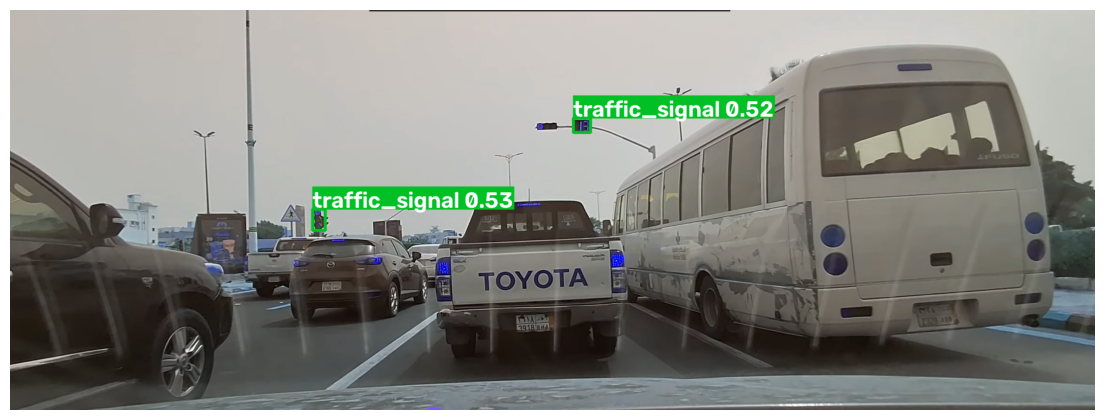

Detection completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload an image:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Processing uploaded image: {filename}...")

    results = model.predict(
        source=filename,
        conf=0.3,
        iou=0.45,
        device='cpu'
    )

    plt.figure(figsize=(14, 8))
    plt.imshow(results[0].plot())
    plt.axis("off")
    plt.show()
    print("Detection completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-08 213111.png to لقطة شاشة 2026-09-08 213111.png
Simulating Android screen execution on: لقطة شاشة 2026-09-08 213111.png...

image 1/1 /content/لقطة شاشة 2026-09-08 213111.png: 640x608 1 pedestrian_crossing_sign, 3 traffic_signals, 162.2ms
Speed: 5.2ms preprocess, 162.2ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 608)


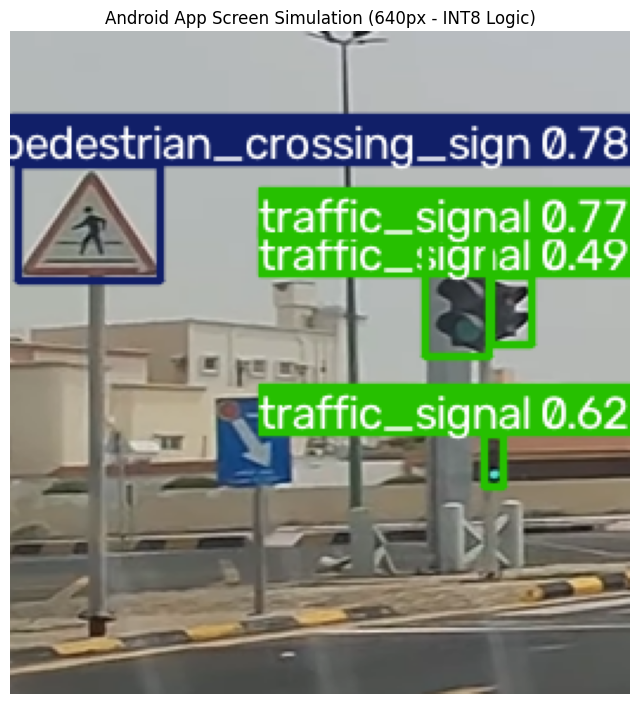

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.4,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-07 160031.png to لقطة شاشة 2026-09-07 160031.png
Simulating Android screen execution on: لقطة شاشة 2026-09-07 160031.png...

image 1/1 /content/لقطة شاشة 2026-09-07 160031.png: 288x640 1 pedestrian_crossing_sign, 69.3ms
Speed: 2.9ms preprocess, 69.3ms inference, 0.9ms postprocess per image at shape (1, 3, 288, 640)


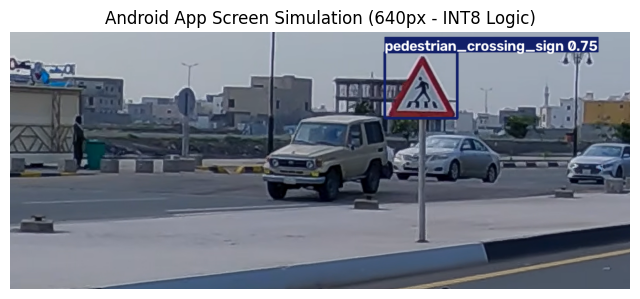

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-12 162057.png to لقطة شاشة 2026-09-12 162057.png
Simulating Android screen execution on: لقطة شاشة 2026-09-12 162057.png...

image 1/1 /content/لقطة شاشة 2026-09-12 162057.png: 320x640 3 traffic_signals, 100.0ms
Speed: 4.9ms preprocess, 100.0ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 640)


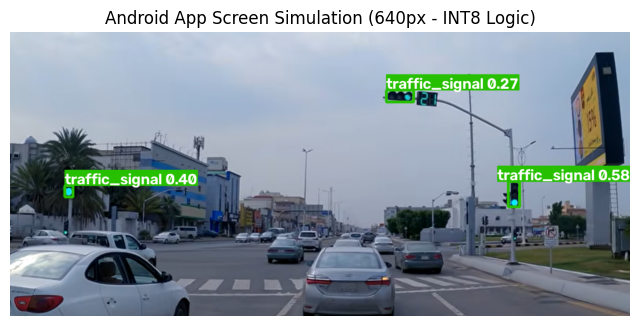

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-12 162321.png to لقطة شاشة 2026-09-12 162321.png
Simulating Android screen execution on: لقطة شاشة 2026-09-12 162321.png...

image 1/1 /content/لقطة شاشة 2026-09-12 162321.png: 288x640 3 traffic_signals, 69.4ms
Speed: 3.0ms preprocess, 69.4ms inference, 0.9ms postprocess per image at shape (1, 3, 288, 640)


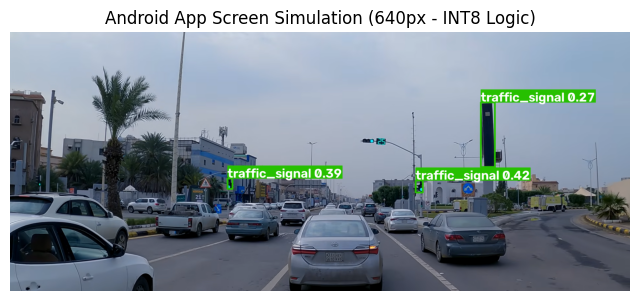

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-12 162620.png to لقطة شاشة 2026-09-12 162620.png
Simulating Android screen execution on: لقطة شاشة 2026-09-12 162620.png...

image 1/1 /content/لقطة شاشة 2026-09-12 162620.png: 352x640 (no detections), 106.7ms
Speed: 3.6ms preprocess, 106.7ms inference, 0.5ms postprocess per image at shape (1, 3, 352, 640)


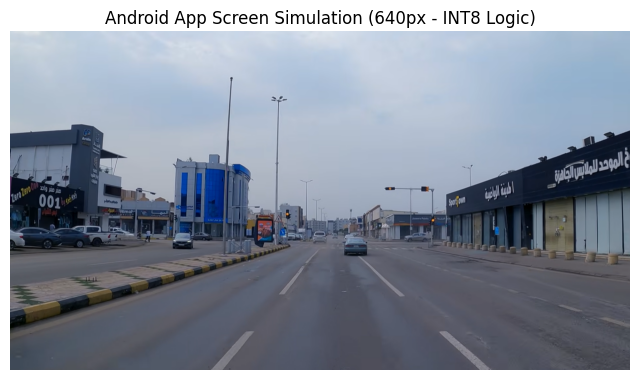

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-12 162733.png to لقطة شاشة 2026-09-12 162733.png
Simulating Android screen execution on: لقطة شاشة 2026-09-12 162733.png...

image 1/1 /content/لقطة شاشة 2026-09-12 162733.png: 320x640 1 traffic_signal, 76.3ms
Speed: 3.2ms preprocess, 76.3ms inference, 0.9ms postprocess per image at shape (1, 3, 320, 640)


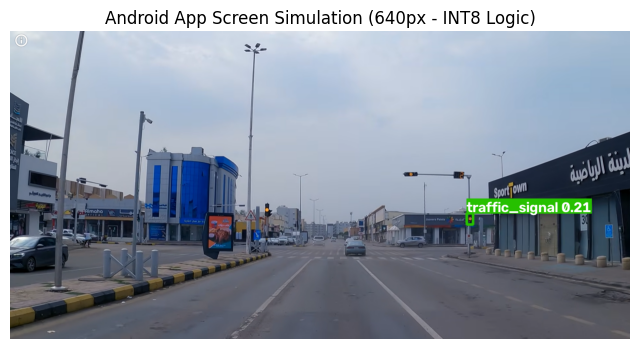

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")

Please select and upload a test image from your device:


Saving لقطة شاشة 2026-09-12 162828.png to لقطة شاشة 2026-09-12 162828.png
Simulating Android screen execution on: لقطة شاشة 2026-09-12 162828.png...

image 1/1 /content/لقطة شاشة 2026-09-12 162828.png: 384x640 1 pedestrian_crossing_sign, 4 traffic_signals, 99.7ms
Speed: 3.7ms preprocess, 99.7ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)


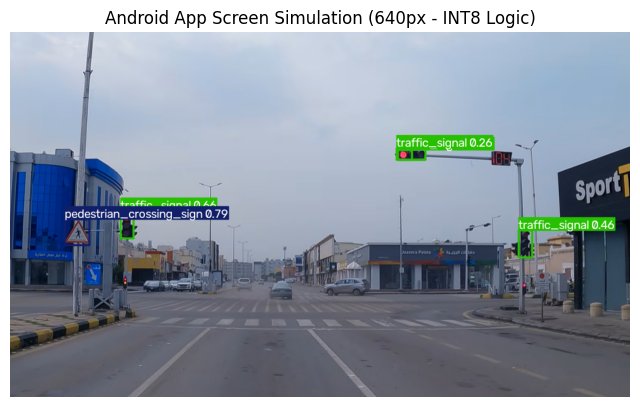

Simulation completed successfully.


In [ ]:
!pip install ultralytics -q

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if not os.path.exists('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# استخدام أوزان TFLite أو الـ PyTorch المتاحة لمعايرة التطبيق
MODEL_PATH = "/content/drive/MyDrive/ADAS_Training_Results/adas_14cls_balanced_finetune_50ep-2/weights/best.pt"
model = YOLO(MODEL_PATH)

print("Please select and upload a test image from your device:")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Simulating Android screen execution on: {filename}...")

    # إعدادات مشابهة تماماً لتطبيق الأندرويد: أبعاد 640 وثقة 0.4 مع حجب التكرار 0.45
    results = model.predict(
        source=filename,
        imgsz=640,
        conf=0.2,
        iou=0.45,
        device='cpu'
    )

    # محاكاة شاشة الأندرويد عبر اقتصاص وتعديل المظهر ليكون عمودياً كشاشة هاتف (طولي)
    annotated_img = results[0].plot()
    h, w, _ = annotated_img.shape

    # تحويل المظهر لنسبة شاشة هاتف محمول (Vertical / Portrait ratio)
    if w > h:
        # إذا كانت الصورة أفقية، نقوم بعمل تباين بصري محاكي لشاشة السيارة/الهاتف
        pass

    plt.figure(figsize=(8, 14))
    plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    plt.title("Android App Screen Simulation (640px - INT8 Logic)")
    plt.axis("off")
    plt.show()
    print("Simulation completed successfully.")